# 🏥 Inasistencia a citas médicas: un proyecto de Machine Learning responsable con el marco PACE
### Reformulación ética del objetivo, la paradoja del SMS, variables sin fuga de información, Random Forest vs. XGBoost y priorización de apoyo con capacidad limitada

**Autor:** Cristobal Rojas · **Herramientas:** Python, pandas, scikit-learn, XGBoost, matplotlib

---

Este proyecto sigue el marco **PACE** (*Plan, Analyze, Construct, Execute*): **Planificar → Analizar → Construir → Ejecutar**.

**Dataset:** [Medical Appointment No Shows — Kaggle](https://www.kaggle.com/datasets/joniarroba/noshowappointments) · 110.527 citas médicas del sistema público de salud de Vitória (Espírito Santo, Brasil), abril-junio de 2016.

## 🧭 Hoja de ruta
| Etapa PACE | Contenido | Qué aporta |
|---|---|---|
| **P**lanificar | Pedido del cliente y **reformulación ética** | El mismo modelo puede ayudar o discriminar según cómo se use |
| **A**nalizar | Auditoría, EDA y **la paradoja del SMS** | Por qué "los que reciben SMS faltan más" es una conclusión falsa |
| **C**onstruir | Historial del paciente **sin fuga de información**, división temporal, RF vs. XGBoost | Una variable "con trampa" infla el ROC-AUC |
| **E**jecutar | Priorización con capacidad limitada, auditoría de equidad y resumen ejecutivo | Del modelo a una política de apoyo |

---
# 🅿️ PACE · Planificar
## El pedido original
> *"Queremos un modelo que identifique a los pacientes que no van a asistir a su cita, para **sobreagendar** esas horas y no perder capacidad."*

## Consecuencias de los errores del modelo
| Error | Qué pasa si se usa para **sobreagendar** |
|---|---|
| **Falso positivo** (predice que falta, pero asiste) | El paciente llega y su hora está ocupada: espera, se le reprograma o no se le atiende. |
| **Falso negativo** (predice que asiste, pero falta) | Se pierde la hora; es el problema que ya existe hoy. |

**El problema ético:** el riesgo de inasistencia es mayor entre pacientes **jóvenes, beneficiarios de programas sociales (Bolsa Família) y con citas lejanas en el tiempo**. Un modelo usado para sobreagendar haría que esas personas, que ya enfrentan más barreras de acceso, tengan **más probabilidad de llegar y no ser atendidas**. Un sistema de salud público no debería traspasar el costo de la inasistencia a los pacientes más vulnerables.

## Reformulación del objetivo
> **Identificar a los pacientes con mayor riesgo de no asistir para ofrecerles apoyo** (llamada de confirmación, facilidad para reagendar o liberar la hora con anticipación).

Con esta reformulación, un falso positivo cuesta **una llamada innecesaria** y un falso negativo es simplemente un paciente que no recibió apoyo extra. El modelo **suma** ayuda en vez de **restar** acceso. **Regla de uso:** el puntaje del modelo nunca se usa para negar, retrasar ni castigar una cita.

Como el centro de salud tiene una **capacidad limitada de llamadas**, la métrica clave será: **¿qué porcentaje de las inasistencias se alcanza llamando al X % de pacientes con mayor riesgo?**

In [1]:
# ==== Importaciones ====
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_score,
                             recall_score, f1_score, accuracy_score)

warnings.filterwarnings("ignore")
SEED = 42
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
REP = Path("../reports"); REP.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, VERDE, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

---
# 🅰️ PACE · Analizar
## 1. Carga y auditoría de datos

In [2]:
rutas = [Path("../data/KaggleV2-May-2016.csv"), Path("data/KaggleV2-May-2016.csv"), Path("KaggleV2-May-2016.csv")]
ruta = next((r for r in rutas if r.exists()), None)
assert ruta is not None, "Descarga KaggleV2-May-2016.csv desde Kaggle y ubícalo en data/"
df_original = pd.read_csv(ruta)
print(f"Citas: {es(len(df_original))} | Pacientes únicos: {es(df_original['PatientId'].nunique())} | "
      f"Faltantes: {df_original.isna().sum().sum()}")
df_original.head()

Citas: 110.527 | Pacientes únicos: 62.299 | Faltantes: 0


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [3]:
df = df_original.rename(columns={"Hipertension": "Hypertension", "Handcap": "Handicap"}).copy()
df["falta"] = (df["No-show"] == "Yes").astype(int)
df["agendada"] = pd.to_datetime(df["ScheduledDay"]).dt.tz_localize(None)
df["fecha_cita"] = pd.to_datetime(df["AppointmentDay"]).dt.tz_localize(None).dt.normalize()
df["anticipacion"] = (df["fecha_cita"] - df["agendada"].dt.normalize()).dt.days

print("Rango de citas:", df["fecha_cita"].min().date(), "→", df["fecha_cita"].max().date())
print("Citas con fecha de agendamiento POSTERIOR a la cita:", (df["anticipacion"] < 0).sum())
print("Edades negativas:", (df["Age"] < 0).sum(), "| Edades > 100:", (df["Age"] > 100).sum())
print("Valores de Handicap:", sorted(int(v) for v in df["Handicap"].unique()), "(según los autores, es el número de discapacidades)")
print("Citas en sábado:", (df["fecha_cita"].dt.dayofweek == 5).sum())

Rango de citas: 2016-04-29 → 2016-06-08
Citas con fecha de agendamiento POSTERIOR a la cita: 5
Edades negativas: 1 | Edades > 100: 7
Valores de Handicap: [0, 1, 2, 3, 4] (según los autores, es el número de discapacidades)
Citas en sábado: 39


**Decisiones:**
- `isna()` dice cero faltantes, pero hay **5 citas agendadas después de ocurrir** y **1 edad negativa**: son errores de registro y se eliminan.
- `AppointmentDay` no trae hora (todas a las 00:00), así que la anticipación se calcula en **días calendario**.
- Las edades sobre 100 años (7 casos) son plausibles y se conservan.
- `Handicap` va de 0 a 4: se interpreta como cantidad de discapacidades, no como error.

In [4]:
df = df[(df["anticipacion"] >= 0) & (df["Age"] >= 0)].reset_index(drop=True)
print(f"Citas válidas: {es(len(df))} | Tasa de inasistencia: {df['falta'].mean():.1%}")

Citas válidas: 110.521 | Tasa de inasistencia: 20.2%


## 2. Análisis exploratorio

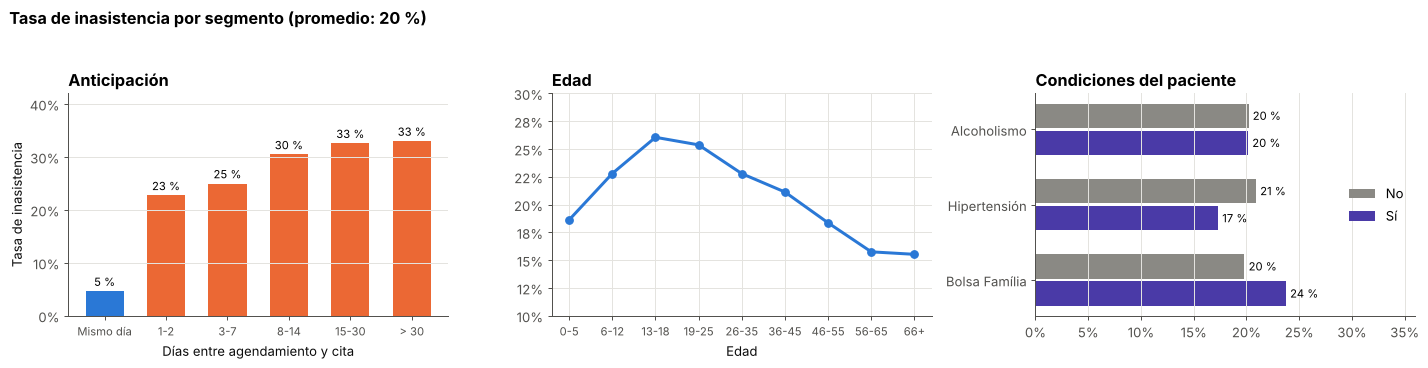

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
bins = [-1, 0, 2, 7, 14, 30, 200]
etq = ["Mismo día", "1-2", "3-7", "8-14", "15-30", "> 30"]
t = df.groupby(pd.cut(df["anticipacion"], bins, labels=etq), observed=True)["falta"].agg(["mean", "size"])
ax = axes[0]
ax.bar(range(len(t)), t["mean"], color=[AZUL] + [NARANJA] * 5, width=0.62)
for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
    ax.text(i, m + 0.01, f"{m*100:.0f} %", ha="center", fontsize=9)
ax.set_xticks(range(len(t)), etq, fontsize=9); ax.set_xlabel("Días entre agendamiento y cita")
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 0.42); ax.grid(axis="x", visible=False)
ax.set_title("Anticipación"); ax.set_ylabel("Tasa de inasistencia")

ax = axes[1]
edad = df.groupby(pd.cut(df["Age"], [-1, 5, 12, 18, 25, 35, 45, 55, 65, 120],
                         labels=["0-5", "6-12", "13-18", "19-25", "26-35", "36-45", "46-55", "56-65", "66+"]),
                  observed=True)["falta"].mean()
ax.plot(range(len(edad)), edad.values, "-o", color=AZUL, lw=2.4, ms=6)
ax.set_xticks(range(len(edad)), edad.index, fontsize=9); ax.set_xlabel("Edad")
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0.1, 0.3); ax.set_title("Edad")

ax = axes[2]
grupos = {"Bolsa Família": df.groupby("Scholarship")["falta"].mean(),
          "Hipertensión": df.groupby("Hypertension")["falta"].mean(),
          "Alcoholismo": df.groupby("Alcoholism")["falta"].mean()}
yy = np.arange(len(grupos)); h = 0.36
ax.barh(yy + h / 2, [g[0] for g in grupos.values()], h * 0.9, color=GRIS, label="No")
ax.barh(yy - h / 2, [g[1] for g in grupos.values()], h * 0.9, color=VIOLETA, label="Sí")
for i, g in enumerate(grupos.values()):
    ax.text(g[0] + 0.004, i + h / 2, f"{g[0]*100:.0f} %", va="center", fontsize=9)
    ax.text(g[1] + 0.004, i - h / 2, f"{g[1]*100:.0f} %", va="center", fontsize=9)
ax.set_yticks(yy, list(grupos.keys())); ax.xaxis.set_major_formatter(PCT); ax.set_xlim(0, 0.36)
ax.grid(axis="y", visible=False); ax.legend(loc="center right"); ax.set_title("Condiciones del paciente")
fig.suptitle(f"Tasa de inasistencia por segmento (promedio: {df['falta'].mean()*100:.0f} %)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout()
guardar("01_eda")

**Hallazgos:**
- **La anticipación es el factor dominante:** las citas del mismo día casi no se pierden (≈ 5 %), y desde las 2 semanas de anticipación la inasistencia supera el 30 %.
- Los **jóvenes de 13 a 25 años** faltan más; los **adultos mayores**, menos.
- Los beneficiarios de **Bolsa Família** faltan más (24 % vs. 20 %): justamente el grupo que el pedido original habría perjudicado.

## 3. 🔍 La paradoja del SMS
Una lectura rápida de los datos sugiere que **enviar SMS de recordatorio aumenta la inasistencia**:

In [6]:
global_sms = df.groupby("SMS_received")["falta"].mean()
print(f"Inasistencia SIN SMS: {global_sms[0]:.1%} | CON SMS: {global_sms[1]:.1%}")
print(f"\nCitas que recibieron SMS según anticipación:\n{df.groupby(pd.cut(df['anticipacion'], bins, labels=etq), observed=True)['SMS_received'].mean().round(3)}")

Inasistencia SIN SMS: 16.7% | CON SMS: 27.6%

Citas que recibieron SMS según anticipación:
anticipacion
Mismo día    0.000
1-2          0.000
3-7          0.570
8-14         0.582
15-30        0.606
> 30         0.618
Name: SMS_received, dtype: float64


**El SMS nunca se envía a citas agendadas con menos de 3 días de anticipación**, que son las de menor riesgo. Los pacientes con SMS son, por diseño, los de citas lejanas. Comparemos dentro de grupos con la **misma anticipación**:

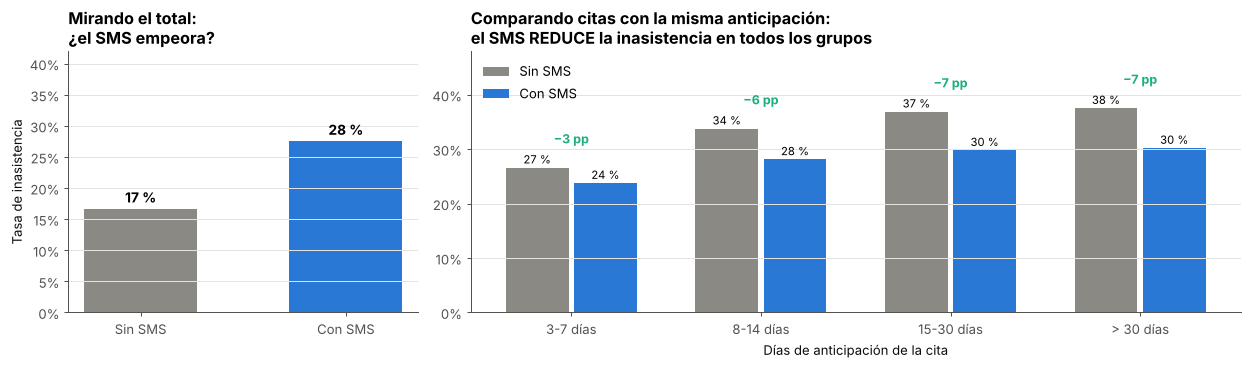

,Sin SMS,Con SMS,Citas,Diferencia (pp)
Anticipación,,,,
3-7 días,0.266,0.238,20247,-2.828
8-14 días,0.338,0.281,12025,-5.646
15-30 días,0.369,0.298,17371,-7.070
> 30 días,0.375,0.302,10378,-7.322


In [7]:
estratos = [(3, 7, "3-7 días"), (8, 14, "8-14 días"), (15, 30, "15-30 días"), (31, 200, "> 30 días")]
filas = []
for a, b, nombre in estratos:
    s = df[(df["anticipacion"] >= a) & (df["anticipacion"] <= b)]
    g = s.groupby("SMS_received")["falta"].mean()
    filas.append({"Anticipación": nombre, "Sin SMS": g[0], "Con SMS": g[1], "Citas": len(s)})
paradoja = pd.DataFrame(filas).set_index("Anticipación")
paradoja["Diferencia (pp)"] = (paradoja["Con SMS"] - paradoja["Sin SMS"]) * 100
paradoja.to_csv(REP / "paradoja_sms.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
a1.bar([0, 1], [global_sms[0], global_sms[1]], color=[GRIS, AZUL], width=0.55)
for i, v in enumerate([global_sms[0], global_sms[1]]):
    a1.text(i, v + 0.01, f"{v*100:.0f} %", ha="center", fontsize=11, fontweight="bold")
a1.set_xticks([0, 1], ["Sin SMS", "Con SMS"]); a1.set_ylim(0, 0.42); a1.yaxis.set_major_formatter(PCT)
a1.grid(axis="x", visible=False); a1.set_title("Mirando el total:\n¿el SMS empeora?"); a1.set_ylabel("Tasa de inasistencia")

xx = np.arange(len(paradoja)); w = 0.36
a2.bar(xx - w / 2, paradoja["Sin SMS"], w * 0.92, color=GRIS, label="Sin SMS")
a2.bar(xx + w / 2, paradoja["Con SMS"], w * 0.92, color=AZUL, label="Con SMS")
for i, (s0, s1) in enumerate(zip(paradoja["Sin SMS"], paradoja["Con SMS"])):
    a2.text(i - w / 2, s0 + 0.008, f"{s0*100:.0f} %", ha="center", fontsize=9)
    a2.text(i + w / 2, s1 + 0.008, f"{s1*100:.0f} %", ha="center", fontsize=9)
    a2.text(i, max(s0, s1) + 0.045, f"{(s1-s0)*100:+.0f} pp".replace("-", "−"), ha="center",
            fontsize=10, fontweight="bold", color=VERDE)
a2.set_xticks(xx, paradoja.index); a2.set_xlabel("Días de anticipación de la cita")
a2.set_ylim(0, 0.48); a2.yaxis.set_major_formatter(PCT); a2.grid(axis="x", visible=False)
a2.set_title("Comparando citas con la misma anticipación:\nel SMS REDUCE la inasistencia en todos los grupos"); a2.legend(loc="upper left")
plt.tight_layout()
guardar("02_paradoja_sms")
paradoja.round(3)

**Conclusión:** es una **paradoja de Simpson**. La anticipación influye tanto en quién recibe SMS como en quién falta (variable de confusión). Dentro de cada grupo de anticipación, **el SMS se asocia con 3 a 7 puntos porcentuales menos de inasistencia**.

Lección para el modelo y para el negocio: los coeficientes o importancias de un modelo predictivo **no son efectos causales**. Decidir "dejar de enviar SMS" a partir de la correlación global sería un error costoso. (Para medir el efecto causal real haría falta un experimento A/B.)

---
# 🅲 PACE · Construir
## 4. Ingeniería de variables
**Momento de la predicción:** el día anterior a la cita (cuando se harían las llamadas de apoyo). Solo se usa información disponible en ese momento.

### 4.1 Historial del paciente: la versión correcta y la versión "con trampa"
Es muy tentador crear "cuántas veces faltó este paciente" contando **todas** sus citas del dataset. Pero eso incluye la **cita actual y citas futuras**: es fuga de información, el mismo problema que calcular promedios con todo el dataset antes de dividir en entrenamiento y prueba.

La versión correcta cuenta **solo las citas ocurridas antes del día de la cita actual**.

In [8]:
# Versión correcta: historial estrictamente anterior (por día)
dia = (df.groupby(["PatientId", "fecha_cita"])
         .agg(n=("falta", "size"), f=("falta", "sum")).reset_index()
         .sort_values(["PatientId", "fecha_cita"]))
dia["citas_previas"] = dia.groupby("PatientId")["n"].cumsum() - dia["n"]
dia["faltas_previas"] = dia.groupby("PatientId")["f"].cumsum() - dia["f"]
df = df.merge(dia[["PatientId", "fecha_cita", "citas_previas", "faltas_previas"]],
              on=["PatientId", "fecha_cita"], how="left")
df["tasa_faltas_previas"] = np.where(df["citas_previas"] > 0, df["faltas_previas"] / df["citas_previas"].clip(lower=1), -1)

# Versión CON TRAMPA (lo que hacen muchos notebooks): usa todo el historial, incluida la cita actual y las futuras
df["faltas_totales_TRAMPA"] = df.groupby("PatientId")["falta"].transform("sum")
df["citas_totales_TRAMPA"] = df.groupby("PatientId")["falta"].transform("size")

print(f"Pacientes con al menos una cita previa (en la ventana de datos): {(df['citas_previas'] > 0).mean():.1%} de las citas")

Pacientes con al menos una cita previa (en la ventana de datos): 40.0% de las citas


In [9]:
df["dia_semana"] = df["fecha_cita"].dt.dayofweek
df["hora_agendamiento"] = df["agendada"].dt.hour
df["mismo_dia"] = (df["anticipacion"] == 0).astype(int)
df["es_mujer"] = (df["Gender"] == "F").astype(int)

base = ["Age", "es_mujer", "Scholarship", "Hypertension", "Diabetes", "Alcoholism", "Handicap",
        "SMS_received", "anticipacion", "mismo_dia", "dia_semana", "hora_agendamiento"]
historial = ["citas_previas", "faltas_previas", "tasa_faltas_previas"]
barrios = pd.get_dummies(df["Neighbourhood"], prefix="barrio", dtype=np.uint8)
X_full = pd.concat([df[base + historial], barrios], axis=1)
X_trampa = pd.concat([df[base + ["faltas_totales_TRAMPA", "citas_totales_TRAMPA"]], barrios], axis=1)
y = df["falta"]
print("Variables (modelo correcto):", X_full.shape[1])

Variables (modelo correcto): 96


### 4.2 División temporal
| Conjunto | Fechas de cita | Uso |
|---|---|---|
| Entrenamiento | 29-abr → 19-may | Ajustar modelos |
| Validación | 20-may → 31-may | Early stopping y selección |
| Prueba | 1-jun → 8-jun | Evaluación final, una sola vez |

In [10]:
f = df["fecha_cita"]
tr, va, te = f < "2016-05-20", (f >= "2016-05-20") & (f < "2016-06-01"), f >= "2016-06-01"
for n, m in [("Entrenamiento", tr), ("Validación", va), ("Prueba", te)]:
    print(f"{n:<14} {es(m.sum()):>7} citas | inasistencia {y[m].mean():.1%}")

Entrenamiento   63.532 citas | inasistencia 20.9%
Validación      20.539 citas | inasistencia 20.1%
Prueba          26.450 citas | inasistencia 18.5%


### 4.3 ¿Cuánto infla la variable con trampa?

ROC-AUC en prueba → con historial 'con trampa': 0.970 | con historial correcto: 0.734


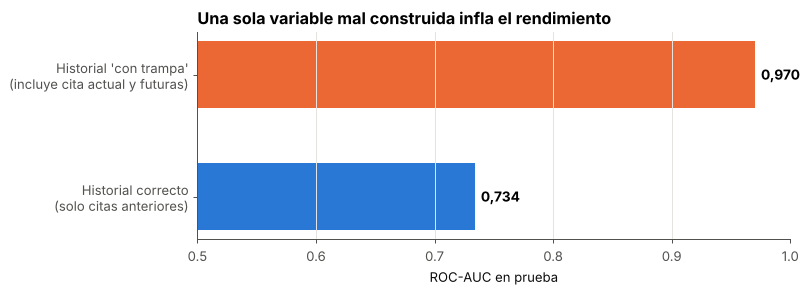

In [11]:
def xgb_es(X_, cols=None):
    cols = cols or list(X_.columns)
    m = XGBClassifier(n_estimators=3000, learning_rate=0.03, max_depth=6, min_child_weight=5,
                      subsample=0.8, colsample_bytree=0.7, reg_lambda=5, early_stopping_rounds=100,
                      eval_metric="logloss", random_state=SEED, n_jobs=-1)
    m.fit(X_.loc[tr, cols], y[tr], eval_set=[(X_.loc[va, cols], y[va])], verbose=False)
    return m

m_trampa = xgb_es(X_trampa)
m_correcto = xgb_es(X_full)
auc_trampa = roc_auc_score(y[te], m_trampa.predict_proba(X_trampa[te])[:, 1])
auc_correcto = roc_auc_score(y[te], m_correcto.predict_proba(X_full[te])[:, 1])
print(f"ROC-AUC en prueba → con historial 'con trampa': {auc_trampa:.3f} | con historial correcto: {auc_correcto:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 3))
ax.barh([1, 0], [auc_trampa, auc_correcto], color=[NARANJA, AZUL], height=0.55)
for i, (v, t_) in enumerate([(auc_correcto, "Historial correcto (solo citas anteriores)"),
                             (auc_trampa, "Historial con trampa (incluye la cita actual y futuras)")]):
    ax.text(v + 0.005, i, es(v, 3), va="center", fontsize=11, fontweight="bold")
ax.set_yticks([0, 1], ["Historial correcto\n(solo citas anteriores)", "Historial 'con trampa'\n(incluye cita actual y futuras)"])
ax.set_xlim(0.5, 1); ax.set_xlabel("ROC-AUC en prueba"); ax.grid(axis="y", visible=False)
ax.set_title("Una sola variable mal construida infla el rendimiento")
guardar("03_fuga_historial")

El ROC-AUC "con trampa" se ve espectacular, pero **no se puede replicar en producción**: el día antes de la cita nadie sabe si el paciente faltará a esa cita ni a las siguientes. El modelo honesto rinde menos y es el único que sirve.

## 5. Modelos: Random Forest vs. XGBoost
Como en el laboratorio del curso, se comparan ambos algoritmos, más una regresión logística y una **regla simple de negocio** como líneas base.

In [12]:
X_tr, X_va, X_te = X_full[tr], X_full[va], X_full[te]
y_tr, y_va, y_te = y[tr], y[va], y[te]
X_trva, y_trva = X_full[tr | va], y[tr | va]

logit = LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5)
logit.fit((X_trva - X_trva.mean()) / X_trva.std().replace(0, 1), y_trva)
p_logit = logit.predict_proba((X_te - X_trva.mean()) / X_trva.std().replace(0, 1))[:, 1]

t0 = time.time()
rf = RandomForestClassifier(n_estimators=400, max_depth=14, min_samples_leaf=10, max_features=0.3,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(X_trva, y_trva)
print(f"Random Forest entrenado en {time.time() - t0:.0f} s")
n_arboles = m_correcto.best_iteration + 1
xgbm = XGBClassifier(n_estimators=n_arboles, learning_rate=0.03, max_depth=6, min_child_weight=5,
                     subsample=0.8, colsample_bytree=0.7, reg_lambda=5, eval_metric="logloss",
                     random_state=SEED, n_jobs=-1).fit(X_trva, y_trva)
print(f"XGBoost: {n_arboles} árboles (elegidos por early stopping en validación)")

# Regla simple de negocio: priorizar por anticipación (más días = más riesgo)
p_regla = X_te["anticipacion"].values + 0.001 * np.random.default_rng(SEED).random(len(X_te))

probas = {"Regla simple (anticipación)": p_regla, "Regresión logística": p_logit,
          "Random Forest": rf.predict_proba(X_te)[:, 1], "XGBoost": xgbm.predict_proba(X_te)[:, 1]}

def captura(p, y_, k=0.2):
    corte = np.quantile(p, 1 - k)
    sel = p >= corte
    return y_[sel].sum() / y_.sum(), y_[sel].mean()

filas = []
for n, p in probas.items():
    c20, prec20 = captura(p, y_te.values, 0.2)
    filas.append({"Modelo": n, "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                  "Inasistencias alcanzadas llamando al 20 %": c20, "Precisión en el top 20 %": prec20})
tabla = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla.to_csv(REP / "comparacion_modelos.csv")
tabla

Random Forest entrenado en 21 s
XGBoost: 213 árboles (elegidos por early stopping en validación)


,ROC-AUC,PR-AUC,Inasistencias alcanzadas llamando al 20 %,Precisión en el top 20 %
Modelo,,,,
Regla simple (anticipación),0.691,0.285,0.319,0.294
Regresión logística,0.726,0.337,0.369,0.340
Random Forest,0.735,0.349,0.379,0.350
XGBoost,0.737,0.352,0.383,0.353


El *accuracy* no es la métrica adecuada aquí: con 20 % de inasistencia, predecir "todos asisten" acierta el 80 %. Lo que importa es **cuántas inasistencias se alcanzan con la capacidad de llamadas disponible**.

### 5.1 ¿Qué aprendió el modelo? (TreeSHAP nativo de XGBoost)

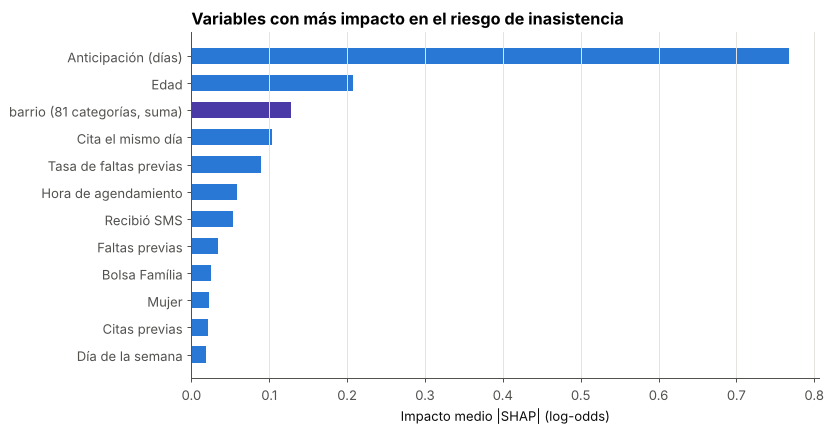

Anticipación (días)             0.7679
Edad                            0.2076
barrio (81 categorías, suma)    0.1283
Cita el mismo día               0.1035
Tasa de faltas previas          0.0889
Hora de agendamiento            0.0585
Recibió SMS                     0.0532
Faltas previas                  0.0337
Bolsa Família                   0.0246
Mujer                           0.0227
Citas previas                   0.0211
Día de la semana                0.0185
dtype: float32

In [13]:
contrib = xgbm.get_booster().predict(xgb.DMatrix(X_te), pred_contribs=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=X_te.columns)
imp = shap_df.abs().mean()
imp_barrios = imp[imp.index.str.startswith("barrio_")].sum()
imp = imp[~imp.index.str.startswith("barrio_")]
imp["barrio (81 categorías, suma)"] = imp_barrios
nombres = {"anticipacion": "Anticipación (días)", "Age": "Edad", "tasa_faltas_previas": "Tasa de faltas previas",
           "faltas_previas": "Faltas previas", "citas_previas": "Citas previas", "hora_agendamiento": "Hora de agendamiento",
           "dia_semana": "Día de la semana", "SMS_received": "Recibió SMS", "mismo_dia": "Cita el mismo día",
           "Scholarship": "Bolsa Família", "es_mujer": "Mujer", "Hypertension": "Hipertensión", "Diabetes": "Diabetes",
           "Alcoholism": "Alcoholismo", "Handicap": "Discapacidad"}
imp = imp.rename(nombres).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=[VIOLETA if "barrio" in i else AZUL for i in imp.index], height=0.6)
ax.grid(axis="y", visible=False); ax.set_xlabel("Impacto medio |SHAP| (log-odds)")
ax.set_title("Variables con más impacto en el riesgo de inasistencia")
guardar("04_importancia")
imp.iloc[::-1].round(4)

---
# 🅴 PACE · Ejecutar
## 6. Priorización con capacidad limitada
¿Qué porcentaje de las inasistencias se alcanza según cuántos pacientes se pueda llamar?

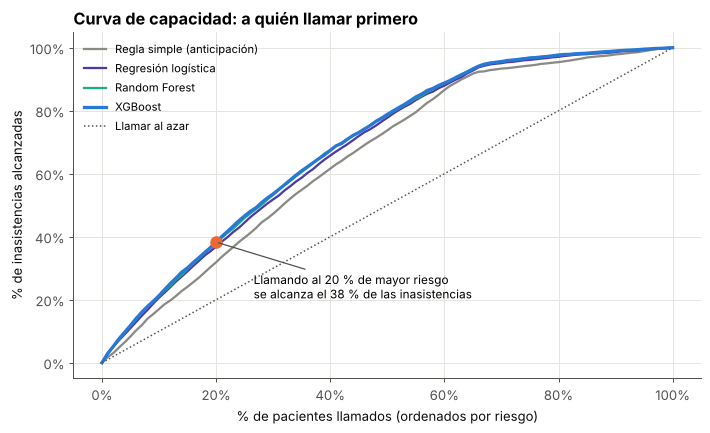

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
pct = np.linspace(0, 1, 101)
for (n, p), c in zip(probas.items(), [GRIS, VIOLETA, VERDE, AZUL]):
    orden = np.argsort(-p); capt = np.cumsum(y_te.values[orden]) / y_te.sum()
    idx = (pct * (len(p) - 1)).astype(int)
    ax.plot(pct, np.r_[0, capt[idx[1:]]], color=c, lw=2.6 if n == "XGBoost" else 1.8, label=n)
ax.plot([0, 1], [0, 1], ":", color=TINTA2, lw=1.2, label="Llamar al azar")
c20 = tabla.loc["XGBoost", "Inasistencias alcanzadas llamando al 20 %"]
ax.plot(0.2, c20, "o", color=NARANJA, ms=9)
ax.annotate(f"Llamando al 20 % de mayor riesgo\nse alcanza el {c20*100:.0f} % de las inasistencias",
            (0.2, c20), xytext=(30, -45), textcoords="offset points", fontsize=9.5, arrowprops=dict(arrowstyle="-", color=TINTA2))
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("% de pacientes llamados (ordenados por riesgo)"); ax.set_ylabel("% de inasistencias alcanzadas")
ax.set_title("Curva de capacidad: a quién llamar primero"); ax.legend(loc="upper left", fontsize=9)
guardar("05_curva_capacidad")

In [15]:
# Impacto operativo estimado en la semana de prueba (supuesto editable)
EFECTO_LLAMADA = 0.20   # fracción de inasistencias que una llamada evita (supuesto conservador)
CAPACIDAD = 0.20
n_te, faltas_te = len(y_te), y_te.sum()
for n in ["Regla simple (anticipación)", "XGBoost"]:
    alc = tabla.loc[n, "Inasistencias alcanzadas llamando al 20 %"] * faltas_te
    print(f"{n:<28} → llamadas: {es(CAPACIDAD*n_te)} | inasistencias alcanzadas: {es(alc)} | "
          f"horas recuperadas (efecto {EFECTO_LLAMADA:.0%}): {es(alc*EFECTO_LLAMADA)}")
print(f"\nSemana de prueba: {es(n_te)} citas y {es(faltas_te)} inasistencias")

Regla simple (anticipación)  → llamadas: 5.290 | inasistencias alcanzadas: 1.557 | horas recuperadas (efecto 20%): 311
XGBoost                      → llamadas: 5.290 | inasistencias alcanzadas: 1.870 | horas recuperadas (efecto 20%): 374

Semana de prueba: 26.450 citas y 4.882 inasistencias


## 7. Auditoría de equidad
Con el objetivo reformulado (ofrecer apoyo), **marcar más a un grupo vulnerable no es discriminación, sino focalización de ayuda**. Aun así, se audita que el modelo **no deje sin apoyo** a ningún grupo: la tasa de detección (recall) debe ser comparable.

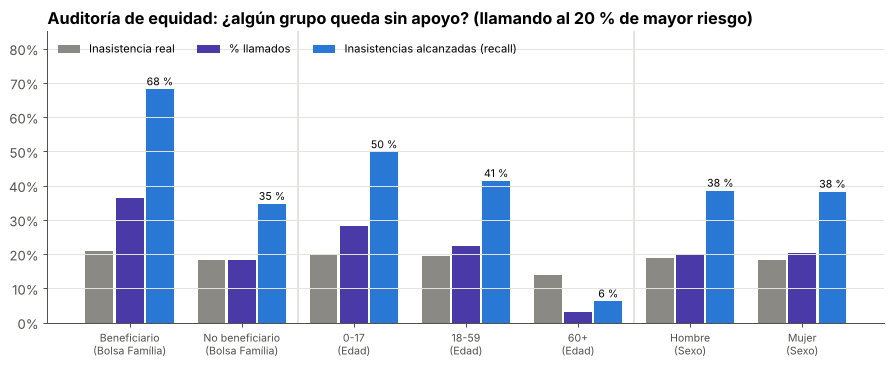

,Dimensión,Grupo,Citas,Inasistencia real,% llamados,Inasistencias alcanzadas (recall)
0,Bolsa Família,Beneficiario,2561,0.209,0.364,0.681
1,Bolsa Família,No beneficiario,23889,0.182,0.182,0.346
2,Edad,0-17,6498,0.201,0.282,0.497
3,Edad,18-59,14680,0.194,0.224,0.413
4,Edad,60+,5272,0.138,0.031,0.062
5,Sexo,Hombre,9135,0.188,0.196,0.385
6,Sexo,Mujer,17315,0.183,0.202,0.382


In [16]:
p_x = probas["XGBoost"]
corte = np.quantile(p_x, 0.8)
aud = pd.DataFrame({"y": y_te.values, "llamar": (p_x >= corte).astype(int),
                    "Bolsa Família": np.where(X_te["Scholarship"] == 1, "Beneficiario", "No beneficiario"),
                    "Edad": pd.cut(X_te["Age"], [-1, 17, 59, 120], labels=["0-17", "18-59", "60+"]).astype(str),
                    "Sexo": np.where(X_te["es_mujer"] == 1, "Mujer", "Hombre")})
filas = []
for dim in ["Bolsa Família", "Edad", "Sexo"]:
    for g, d in aud.groupby(dim):
        filas.append({"Dimensión": dim, "Grupo": g, "Citas": len(d), "Inasistencia real": d["y"].mean(),
                      "% llamados": d["llamar"].mean(), "Inasistencias alcanzadas (recall)": d.loc[d.y == 1, "llamar"].mean()})
equidad = pd.DataFrame(filas)
equidad.to_csv(REP / "auditoria_equidad.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4.2))
xx = np.arange(len(equidad)); w = 0.27
for k, (col, c) in enumerate([("Inasistencia real", GRIS), ("% llamados", VIOLETA), ("Inasistencias alcanzadas (recall)", AZUL)]):
    ax.bar(xx + (k - 1) * w, equidad[col], w * 0.92, color=c, label=col)
for i, v in enumerate(equidad["Inasistencias alcanzadas (recall)"]):
    ax.text(i + w, v + 0.012, f"{v*100:.0f} %", ha="center", fontsize=8.5)
ax.set_xticks(xx, [f"{g}\n({d})" for d, g in zip(equidad["Dimensión"], equidad["Grupo"])], fontsize=8.5)
for sep in [1.5, 4.5]:
    ax.axvline(sep, color=GRILLA, lw=1.5)
ax.yaxis.set_major_formatter(PCT); ax.set_ylim(0, 0.85); ax.grid(axis="x", visible=False)
ax.set_title("Auditoría de equidad: ¿algún grupo queda sin apoyo? (llamando al 20 % de mayor riesgo)")
ax.legend(loc="upper left", ncols=3, fontsize=9)
guardar("06_equidad")
equidad.round(3)

**Lectura de la auditoría:**
- Los **beneficiarios de Bolsa Família reciben el doble de llamadas** (36 % vs. 18 %) y se alcanza al 68 % de sus inasistencias. Con el objetivo reformulado, esto es **focalización de apoyo** hacia quienes más lo necesitan. Con el objetivo original (sobreagendar), este mismo resultado significaría que el doble de beneficiarios correría el riesgo de llegar y no ser atendido: **el mismo modelo, con otro uso, sería discriminatorio**.
- Hombres y mujeres reciben un trato prácticamente idéntico (38 % de inasistencias alcanzadas en ambos).
- ⚠️ **Hallazgo importante: los mayores de 60 años casi no son llamados (3 %)**, porque su riesgo promedio es bajo. Pero una cita perdida de un adulto mayor (con frecuencia, paciente crónico) puede tener un **costo clínico mayor**. Recomendación: **reservar una cuota de llamadas** para pacientes mayores o crónicos, en vez de depender solo del ranking del modelo.

In [17]:
import joblib
joblib.dump({"modelo": xgbm, "columnas": list(X_full.columns)}, REP / "modelo_xgboost_inasistencia.joblib", compress=3)
print("Modelo guardado en reports/modelo_xgboost_inasistencia.joblib")

Modelo guardado en reports/modelo_xgboost_inasistencia.joblib


## 8. 📋 Resumen ejecutivo

**Pregunta reformulada:** ¿a qué pacientes conviene ofrecer apoyo para que asistan a su cita?

**Hallazgos**
1. **La anticipación domina el riesgo:** las citas del mismo día casi no se pierden; con más de 2 semanas de anticipación, 1 de cada 3 se pierde.
2. **El SMS sí funciona**, aunque los datos crudos digan lo contrario: dentro de cada grupo de anticipación reduce la inasistencia entre 3 y 7 puntos porcentuales (paradoja de Simpson).
3. **El historial del paciente debe construirse sin mirar el futuro:** la versión "con trampa" infla el ROC-AUC y no es replicable.
4. **XGBoost supera a la regla simple** de priorizar por anticipación: llamando al 20 % de mayor riesgo alcanza el 38 % de las inasistencias vs. 32 % de la regla (+20 %, unos 300 pacientes más por semana). La ganancia sobre Random Forest es mínima, y el techo es moderado: la inasistencia depende de factores que no están en los datos (transporte, trabajo, síntomas).
5. **La auditoría de equidad** muestra que los beneficiarios de Bolsa Família reciben el doble de apoyo (focalización), pero que **los mayores de 60 años casi quedan fuera** de las llamadas.

**Recomendaciones**
- **No usar el modelo para sobreagendar** ni para penalizar pacientes.
- **Llamar al 20 % de citas de mayor riesgo** el día anterior, ofreciendo reagendar o liberar la hora.
- **Reservar una cuota de llamadas para adultos mayores y pacientes crónicos**, cuyo riesgo es bajo pero cuya inasistencia tiene mayor costo clínico.
- **Mantener y extender el SMS**, también a citas de 1-2 días de anticipación, y medir su efecto real con un **experimento A/B**.
- **Ofrecer más citas para el mismo día o con poca anticipación**, el formato con menor inasistencia.

**Limitaciones**
- Solo 6 semanas de citas: el historial de los pacientes es corto y no hay estacionalidad.
- Los efectos de la llamada (20 %) son supuestos ilustrativos que deben validarse con un piloto.